# Etapa 4 — Aprendizado Probabilístico e EM
Nesta etapa, avançamos da probabilidade descritiva para o aprendizado de máquina probabilístico. O objetivo é estimar parâmetros a partir dos dados (MLE e MAP), implementar o classificador Naive Bayes do zero e utilizar o algoritmo Expectation-Maximization (EM) para descobrir variáveis ocultas (perfis de escolas) na base do Censo Escolar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from scripts.em import ajustar_em, prever_perfil

np.random.seed(42)
df1 = pd.read_csv("dados_etapa1.csv")
print(f"Escolas na base: {len(df1)}")

Escolas na base: 5562


## 1 e 2. MLE e MAP (Estimação de Parâmetros)
Vamos estimar a probabilidade de uma escola ter `infra_digital_basica = 1`.
* **MLE (Maximum Likelihood Estimation):** Usa apenas a contagem direta dos dados (frequência).
* **MAP (Maximum A Posteriori):** Adiciona um "prior" (crença inicial). Usamos a distribuição Beta(2,2), que "puxa" a probabilidade para o meio (0.5) quando temos poucos dados, evitando estimativas extremas.

In [2]:
# Separando treino e teste (70% treino, 30% teste)
X = df1.drop(columns=['CO_ENTIDADE', 'infra_digital_basica'])
y = df1['infra_digital_basica']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

s = y_train.sum() # Sucessos (escolas com infra = 1)
n = len(y_train)  # Total

# MLE
mle = s / n

# MAP com Prior Beta(2,2)
alpha, beta = 2, 2
map_est = (s + alpha - 1) / (n + alpha + beta - 2)

print(f"Total de escolas no treino (n): {n}")
print(f"Escolas com infra = 1 (s): {s}")
print(f"MLE: {mle:.4f}")
print(f"MAP (Beta[2,2]): {map_est:.4f}")

Total de escolas no treino (n): 3893
Escolas com infra = 1 (s): 725
MLE: 0.1862
MAP (Beta[2,2]): 0.1864


## 3. Classificador Naive Bayes do Zero
Implementamos o modelo sem bibliotecas prontas. O grande diferencial aqui é o uso da **Suavização de Laplace** (+1), que evita que o modelo atribua probabilidade zero para combinações de pistas que não apareceram no treino (o que zeraria toda a predição).

In [3]:
from scripts.naive_bayes import NaiveBayesDoZero

# Treinando e testando o modelo puro
nb_puro = NaiveBayesDoZero()
nb_puro.fit(X_train, y_train)
pred_puro = nb_puro.predict(X_test)
acc_puro = accuracy_score(y_test, pred_puro)
print(f"Acurácia Naive Bayes Puro: {acc_puro:.4f}")

Acurácia Naive Bayes Puro: 0.8442


## 4 e 5. Dois perfis de escolas e a curva do EM
Laboratório, biblioteca e gerador são três indicadores binários. Usamos uma mistura de Bernoulli com dois perfis ocultos. Cada perfil tem um peso e uma probabilidade de presença para cada recurso. No passo E, calculamos a probabilidade de cada escola pertencer a cada perfil. No passo M, atualizamos os parâmetros usando essas probabilidades como pesos.

O ajuste recebe somente as escolas de treino, sem a classe. O gráfico mostra a log-verossimilhança desse ajuste. Encerramos quando a mudança média por escola fica abaixo de 0,0000001 ou quando atingimos 500 avaliações.

   IN_LABORATORIO_INFORMATICA  IN_BIBLIOTECA  IN_ENERGIA_GERADOR_FOSSIL   peso
0                       0.596          0.777                      0.030  0.294
1                       0.000          0.025                      0.162  0.706
Avaliações da log-verossimilhança: 105


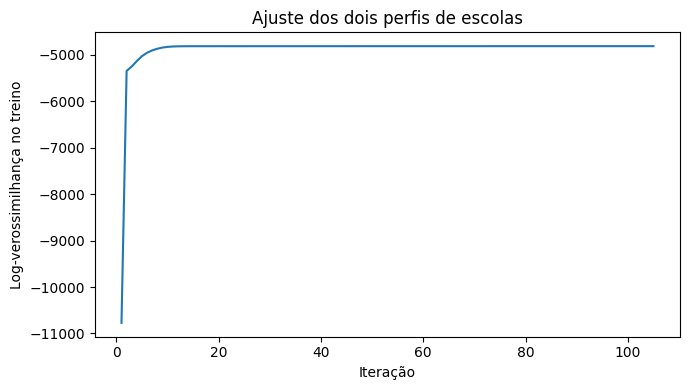

In [4]:
recursos = ["IN_LABORATORIO_INFORMATICA", "IN_BIBLIOTECA", "IN_ENERGIA_GERADOR_FOSSIL"]
treino_em = X_train[recursos].to_numpy()
pesos, probabilidades, historico = ajustar_em(treino_em)
print(pd.DataFrame(probabilidades, columns=recursos).assign(peso=pesos).round(3))
print(f"Avaliações da log-verossimilhança: {len(historico)}")
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(historico) + 1), historico)
plt.xlabel("Iteração")
plt.ylabel("Log-verossimilhança no treino")
plt.title("Ajuste dos dois perfis de escolas")
plt.tight_layout()
plt.show()

## 6. Comparação: Naive Bayes Puro vs. Naive Bayes com EM
Por fim, integramos o resultado do EM ao classificador. O EM encontrou os perfis ocultos das escolas. Nós adicionamos esse "perfil" como uma nova pista para o Naive Bayes e verificamos se isso melhora a acurácia.

In [5]:
X_train_em = X_train.assign(perfil_oculto=prever_perfil(treino_em, pesos, probabilidades))
X_test_em = X_test.assign(perfil_oculto=prever_perfil(X_test[recursos].to_numpy(), pesos, probabilidades))

nb_em = NaiveBayesDoZero()
nb_em.fit(X_train_em, y_train)
acc_em = accuracy_score(y_test, nb_em.predict(X_test_em))
print(f"Escolas no teste: {len(y_test)}")
print(f"Naive Bayes puro: {acc_puro:.2%}")
print(f"Naive Bayes + EM: {acc_em:.2%}")

Escolas no teste: 1669
Naive Bayes puro: 84.42%
Naive Bayes + EM: 83.34%


### Conclusão da Etapa 4
Nas mesmas 1669 escolas de teste, o Naive Bayes puro acertou 84,42% e o Naive Bayes com o perfil do EM acertou 83,34%. O perfil resume três informações que o classificador já recebia. Nesta divisão, acrescentá-lo reduziu a acurácia.

A log-verossimilhança de treino cresceu até o critério de parada, alcançado na avaliação 105. Essa curva mostra o ajuste dos perfis, enquanto a acurácia mede os acertos de classificação em escolas separadas para teste.